# Delay Coordinate Embedding

In many real-world systems, only a single observable of the underlying dynamics is available, making it impossible to directly reconstruct the full phase space. **Delay coordinate embedding**, introduced by Takens, provides a way to recover the geometry of the underlying attractor using delayed copies of a single time series.

The Lorenz system is governed by the equations

$$
\begin{aligned}
\dot{x} &= \sigma(y-x),\\
\dot{y} &= x(\rho-z)-y,\\
\dot{z} &= xy-\beta z,
\end{aligned}
$$

where $\sigma$, $\rho$, and $\beta$ are system parameters. 

Using only the scalar time series (x(t)), a delay-coordinate embedding is constructed as

$$
\mathbf{X}(t)=\left[x(t),,x(t+\tau),,x(t+2\tau)\right],
$$

where $\tau$ is the embedding delay. The reconstructed attractor preserves the essential topology of the original Lorenz attractor, demonstrating that the dynamics of a multidimensional system can be recovered from delayed observations of a single measured variable.


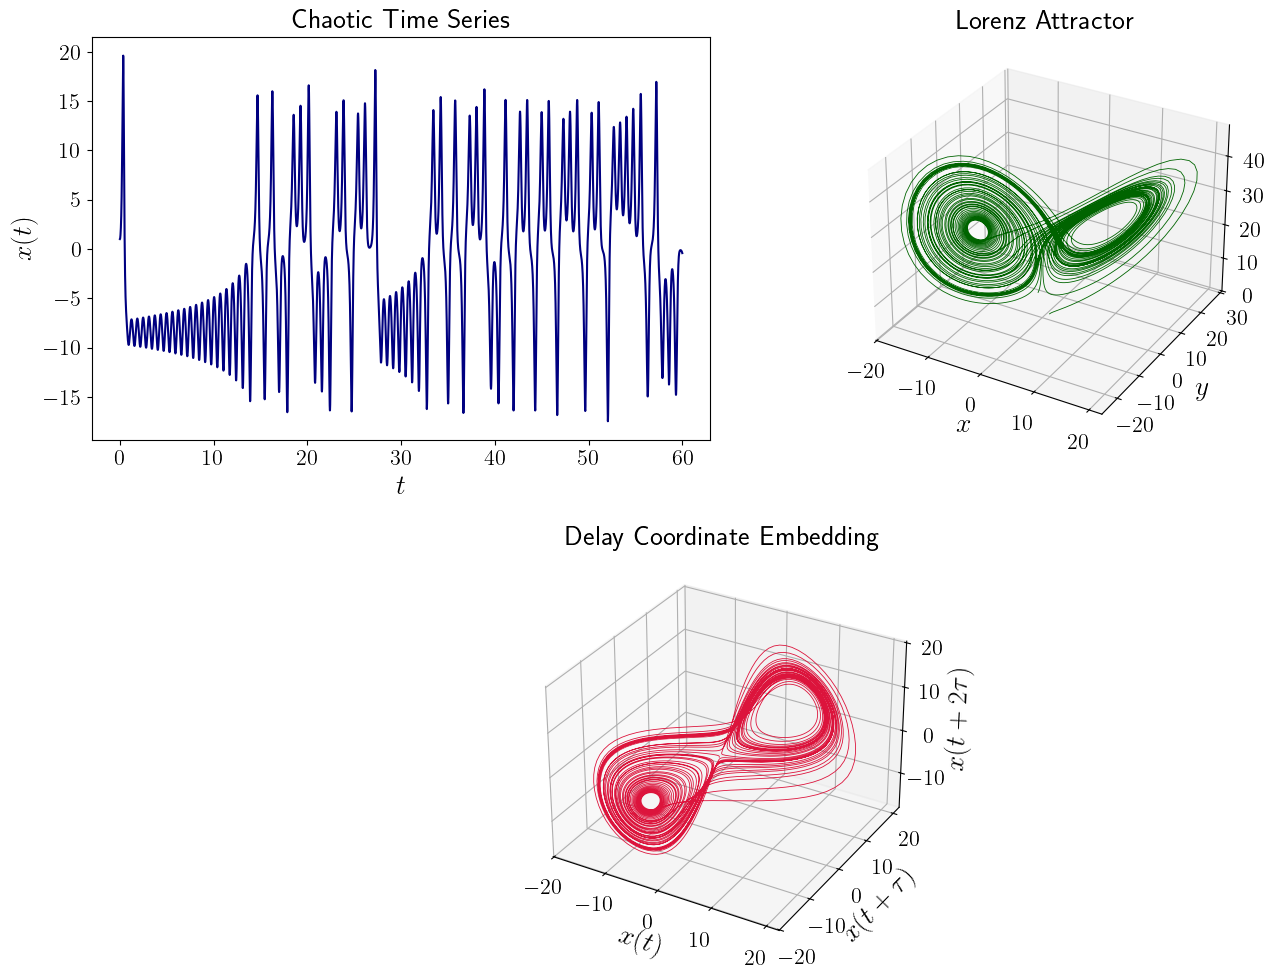

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

plt.rcParams.update({
    'font.size': 18,
    'axes.labelsize': 20,
    'axes.titlesize': 20,
    'xtick.labelsize': 16,
    'ytick.labelsize': 16,
    'text.usetex': True
})

# Lorenz parameters
sigma = 10
rho = 28
beta = 8/3

t_final = 60
dt = 0.01
t_eval = np.arange(0, t_final, dt)

def lorenz(t, X):
    x, y, z = X
    return [
        sigma * (y - x),
        x * (rho - z) - y,
        x * y - beta * z
    ]

sol = solve_ivp(
    lorenz,
    (0, t_final),
    [1.0, 1.0, 1.0],
    t_eval=t_eval
)

x = sol.y[0]
y = sol.y[1]
z = sol.y[2]
t = sol.t

# Delay embedding
tau = 10

x1 = x[:-2*tau]
x2 = x[tau:-tau]
x3 = x[2*tau:]

fig = plt.figure(figsize=(14, 10))

# Chaotic time series
ax1 = fig.add_subplot(221)
ax1.plot(t, x, color='navy')
ax1.set_xlabel(r'$t$')
ax1.set_ylabel(r'$x(t)$')
ax1.set_title('Chaotic Time Series')

# Original phase portrait
ax2 = fig.add_subplot(222, projection='3d')
ax2.plot(x, y, z, color='darkgreen', lw=0.6)
ax2.set_xlabel(r'$x$')
ax2.set_ylabel(r'$y$')
ax2.set_zlabel(r'$z$')
ax2.set_title('Lorenz Attractor')

# Delay reconstructed attractor
ax3 = fig.add_subplot(212, projection='3d')
ax3.plot(x1, x2, x3, color='crimson', lw=0.6)
ax3.set_xlabel(r'$x(t)$')
ax3.set_ylabel(r'$x(t+\tau)$')
ax3.set_zlabel(r'$x(t+2\tau)$')
ax3.set_title('Delay Coordinate Embedding')

plt.tight_layout()
plt.show()